## Life cycle assessment of plug and play solar

In the first [chapter](./01_balcony-pv-production.ipynb), we have seen that installing balcony solar can make sense from an economic point of view. But can this technology meaningfully reduce my carbon footprint? This depends on how much carbon is embedded in the production, operation, and recycling of the solar panels (life cycle assessment) compared with the carbon intensity of the Belgian electrical grid. 

The [IEA](https://iea-pvps.org/wp-content/uploads/2024/05/Slides_IEA-PVPS-T12_Fact-Sheet-update-2023_v2.0.pdf) proposes a value of 35.8 gCO2e/kWh (grams of CO2 equivalent emissions per kWh of energy) for monocrystal solar panels, over a 30 year lifetime. Over 30 years, this corresponds to approximately 16.7 MWh of electricity generation. Using the IEA estimate of 35.8 gCO₂e/kWh, the life-cycle emissions associated with manufacturing, operating, and recycling the PV system amount to roughly 600 kg CO2e.

The carbon intensity of the Belgian electricity grid varies over time depending on the generation mix. It gets low when the grid is powered by renewable energy, and it increases when natural gas is burned to generate electricity. In theory, this means that to obtain a precise estimate of the avoided carbon emissions I should consider the hourly variation of carbon intensity. 

The data relative to the carbon intensity of the Belgian grid is provided by [Elia](https://opendata.elia.be/explore/dataset/ods192/information/). Some entries are equal to zero, I'm not sure if this is represents the true carbon intensity, maybe when the grid is entirely powered by renewables, or it's simply a bug.

In [ ]:
annual_energy = 557.88 # kWh/year
lifetime = 30 # years
lifetime_energy = annual_energy * lifetime
carbon_intensity = 35.8 # gCO2e/kWh

embodied_carbon = carbon_intensity * lifetime_energy / 1000  # kg CO2e
print(f'Annual energy: {annual_energy:.2f} kWh/year')
print(f'Lifetime energy: {lifetime_energy:.2f} kWh')
print(f'Embodied carbon: {embodied_carbon:.2f} kg CO2e')
print(f'Carbon intensity: {carbon_intensity:.2f} gCO2e/kWh')

Annual energy: 557.88 kWh/year
Lifetime energy: 16736.40 kWh
Embodied carbon: 599.16 kg CO2e
Carbon intensity: 35.80 gCO2e/kWh


Average carbon intensity: 143.61 gCO2e/kWh
Avoided carbon: 2403.52 kg CO2e
Net carbon: -1804.36 kg CO2e


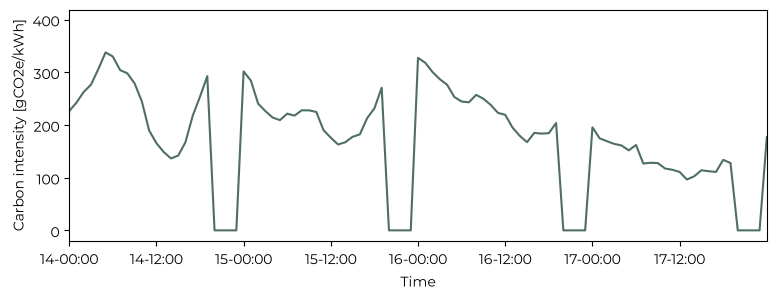

In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

for f in Path("fonts").glob("*.ttf"):   # path relative to the notebook
    fm.fontManager.addfont(str(f))
plt.rcParams["font.family"] = "Montserrat"

import matplotlib.dates as mdates

grid_intensity = pd.read_csv("../data/ods192.csv", parse_dates=True, sep=";")
grid_intensity["Datetime"] = pd.to_datetime(grid_intensity["Datetime"], format="ISO8601", utc=True).dt.tz_convert("Europe/Brussels")
grid_intensity = grid_intensity.set_index("Datetime")

tz = "Europe/Brussels"

average_intensity = grid_intensity["Consumption"].mean()
print(f'Average carbon intensity: {average_intensity:.2f} gCO2e/kWh')

avoided_carbon = lifetime_energy * average_intensity / 1000  # kg CO2e
print(f'Avoided carbon: {avoided_carbon:.2f} kg CO2e')
print(f'Net carbon: {embodied_carbon - avoided_carbon:.2f} kg CO2e')

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(grid_intensity.index, grid_intensity["Consumption"], color='#043122', alpha=0.7)
ax.set_xlabel("Time")
ax.set_ylabel("Carbon intensity [gCO2e/kWh]")   
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%H:%M", tz=tz))
day_start = pd.Timestamp("2026-10-14 00:00", tz=tz)
day_end = pd.Timestamp("2026-10-17 23:59", tz=tz)
ax.set_xlim(day_start, day_end)
plt.show()

However, as a first-order approximation, I will consider the average carbon intensity of the last 3 years, which is equal to 143.61 g/CO2e/kWh, or almost 5 times higher than the solar panel’s carbon intensity. In the end, this means that over its lifetime, the solar installation would avoid approximately 1.8 tonnes of CO2e emissions relative to the current Belgian electricity mix.

From a carbon footprint the solar panel is certainly better than nothing, but it is sobering to consider that 2 tonnes of CO2 is less than what a single airplane emits for a medium haul flight.
